In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import shutil

zip_path = "/content/drive/MyDrive/archive1.zip"

print("ZIP file exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("ZIP file size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")

total, used, free = shutil.disk_usage("/content")

print("Available Colab storage:", round(free / (1024**3), 2), "GB")

ZIP file exists: True
ZIP file size: 7.24 GB
Available Colab storage: 112.54 GB


In [ ]:
import zipfile
from collections import Counter

with zipfile.ZipFile(zip_path, 'r') as z:
    files = z.namelist()

    print("Total files and folders:", len(files))

    image_extensions = ('.jpg', '.jpeg', '.png', '.bmp')
    image_files = [
        f for f in files
        if f.lower().endswith(image_extensions)
    ]

    print("Total images:", len(image_files))

    counts = Counter()

    for f in image_files:
        parts = f.lower().split('/')

        if 'real' in parts:
            counts['Real'] += 1
        elif 'fake' in parts:
            counts['Fake'] += 1

    print("Real images:", counts['Real'])
    print("Fake images:", counts['Fake'])

    print("\nFirst 15 image paths:")
    for f in image_files[:15]:
        print(f)

Total files and folders: 8791
Total images: 8760
Real images: 4937
Fake images: 2505

First 15 image paths:
archive1/data/data/fake/10/aug_1525_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1526_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1527_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1528_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1529_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1530_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1531_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1532_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1533_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1534_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1535_WhatsApp Image 2025-04-05 

In [ ]:
from collections import Counter

other_images = []

for f in image_files:
    parts = f.lower().split('/')

    if 'real' not in parts and 'fake' not in parts:
        other_images.append(f)

print("Images outside Real/Fake folders:", len(other_images))

print("\nTheir folder locations:")
folder_counts = Counter('/'.join(f.split('/')[:4]) for f in other_images)

for folder, count in folder_counts.most_common(20):
    print(folder, ":", count)

print("\nSample image paths:")
for f in other_images[:15]:
    print(f)

Images outside Real/Fake folders: 1318

Their folder locations:
archive1/Features/Features/20_Features : 258
archive1/Features/Features/10_Features : 240
archive1/Features/Features/100_Features : 229
archive1/Features/Features/50_Features : 187
archive1/Features/Features/2000_Features : 147
archive1/Features/Features/500_Features : 132
archive1/Features/Features/200_Features : 125

Sample image paths:
archive1/Features/Features/100_Features/Screenshot 2025-10-15 175138.png
archive1/Features/Features/100_Features/Screenshot 2025-10-15 175141.png
archive1/Features/Features/100_Features/Screenshot 2025-10-15 175145.png
archive1/Features/Features/100_Features/Screenshot 2025-10-15 175147.png
archive1/Features/Features/100_Features/Screenshot 2025-10-15 175154.png
archive1/Features/Features/100_Features/Screenshot 2025-10-15 175157.png
archive1/Features/Features/100_Features/Screenshot 2025-10-15 175202.png
archive1/Features/Features/100_Features/Screenshot 2025-10-15 175329.png
archive1/Fe

In [ ]:
import zipfile
import os

extract_dir = "/content/currency_dataset"

with zipfile.ZipFile(zip_path, 'r') as z:

    selected_files = [
        info for info in z.infolist()
        if info.filename.startswith(
            ("archive1/data/data/real/",
             "archive1/data/data/fake/")
        )
    ]

    print("Files selected:", len(selected_files))

    z.extractall(
        path=extract_dir,
        members=selected_files
    )

print("Dataset extraction completed!")

Files selected: 7461
Dataset extraction completed!


In [ ]:
from pathlib import Path

dataset_path = Path(
    "/content/currency_dataset/archive1/data/data"
)

real_count = sum(
    1 for p in (dataset_path / "real").rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
)

fake_count = sum(
    1 for p in (dataset_path / "fake").rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
)

print("Real images:", real_count)
print("Fake images:", fake_count)
print("Total images:", real_count + fake_count)

Real images: 4937
Fake images: 2505
Total images: 7442


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


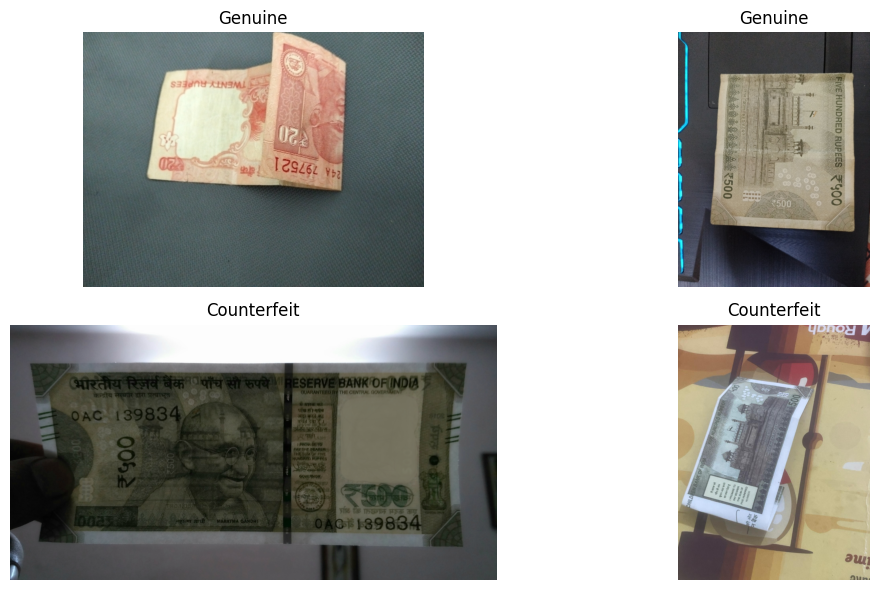

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import random

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

real_folder = dataset_path / "real"
fake_folder = dataset_path / "fake"

real_images = [
    p for p in real_folder.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
]

fake_images = [
    p for p in fake_folder.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
]

samples = (
    [(p, "Genuine") for p in random.sample(real_images, 2)] +
    [(p, "Counterfeit") for p in random.sample(fake_images, 2)]
)

plt.figure(figsize=(12, 6))

for i, (path, label) in enumerate(samples):
    img = Image.open(path).convert("RGB")

    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

zip_path = "/content/drive/MyDrive/archive1.zip"

print("ZIP file available:", os.path.exists(zip_path))

ZIP file available: True


In [ ]:
import zipfile
import os
import random
import shutil

random.seed(42)

extract_dir = "/content/currency_sample"

os.makedirs(extract_dir + "/real", exist_ok=True)
os.makedirs(extract_dir + "/fake", exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as z:

    all_files = z.namelist()

    real_files = [
        f for f in all_files
        if f.startswith("archive1/data/data/real/")
        and f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    fake_files = [
        f for f in all_files
        if f.startswith("archive1/data/data/fake/")
        and f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    selected_real = random.sample(real_files, 500)
    selected_fake = random.sample(fake_files, 500)

    for label, selected_files in [
        ("real", selected_real),
        ("fake", selected_fake)
    ]:
        for i, file in enumerate(selected_files):
            extension = os.path.splitext(file)[1]

            destination = f"{extract_dir}/{label}/{i}{extension}"

            with z.open(file) as source, open(destination, "wb") as target:
                shutil.copyfileobj(source, target)

print("Dataset extraction completed!")
print("Real images:", len(os.listdir(extract_dir + "/real")))
print("Fake images:", len(os.listdir(extract_dir + "/fake")))

Dataset extraction completed!
Real images: 500
Fake images: 500


In [ ]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import Counter

real_files = list(Path("/content/currency_sample/real").glob("*"))
fake_files = list(Path("/content/currency_sample/fake").glob("*"))

image_paths = real_files + fake_files
labels = [0] * len(real_files) + [1] * len(fake_files)

# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

print("\nTraining class counts:", Counter(y_train))
print("Validation class counts:", Counter(y_val))
print("Testing class counts:", Counter(y_test))

Training images: 700
Validation images: 150
Testing images: 150

Training class counts: Counter({1: 350, 0: 350})
Validation class counts: Counter({0: 75, 1: 75})
Testing class counts: Counter({0: 75, 1: 75})


In [ ]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = 224
BATCH_SIZE = 16

def preprocess_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = preprocess_input(image)

    return image, label


def create_dataset(paths, labels, training=False):

    paths = [str(p) for p in paths]

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42
        )

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_dataset(X_train, y_train, training=True)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)

print("Image preprocessing completed!")

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image preprocessing completed!
Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Minimum pixel value: -1.0
Maximum pixel value: 1.0


In [ ]:
import tensorflow as tf

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dropout,
    Dense
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Add our classification layers
inputs = Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)

outputs = Dense(1, activation="sigmoid")(x)

mobilenet_model = Model(inputs, outputs)

# Compile model
mobilenet_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stop]
)

Epoch 1/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step - accuracy: 0.6886 - loss: 0.5612 - val_accuracy: 0.8933 - val_loss: 0.3371
Epoch 2/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 28s 341ms/step - accuracy: 0.8943 - loss: 0.2898 - val_accuracy: 0.9267 - val_loss: 0.2275
Epoch 3/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 20s 351ms/step - accuracy: 0.9329 - loss: 0.2010 - val_accuracy: 0.9467 - val_loss: 0.1795
Epoch 4/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 15s 357ms/step - accuracy: 0.9400 - loss: 0.1807 - val_accuracy: 0.9533 - val_loss: 0.1592
Epoch 5/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 16s 353ms/step - accuracy: 0.9471 - loss: 0.1566 - val_accuracy: 0.9533 - val_loss: 0.1391


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 209ms/step - accuracy: 0.9267 - loss: 0.1799
Test Accuracy: 92.67 %
Test Loss: 0.1799
10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 487ms/step

Classification Report:
              precision    recall  f1-score   support

     Genuine       0.97      0.88      0.92        75
 Counterfeit       0.89      0.97      0.93        75

    accuracy                           0.93       150
   macro avg       0.93      0.93      0.93       150
weighted avg       0.93      0.93      0.93       150



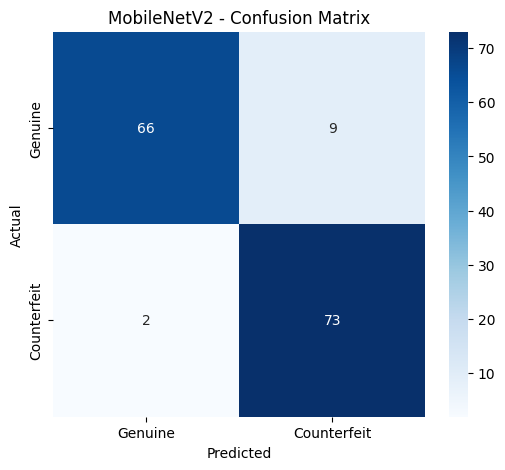

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluate on unseen test images
test_loss, test_accuracy = mobilenet_model.evaluate(test_ds)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

# Generate predictions
y_pred_prob = mobilenet_model.predict(test_ds)

y_pred = (y_pred_prob.ravel() >= 0.5).astype(int)

# Actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Genuine", "Counterfeit"]
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Genuine", "Counterfeit"],
    yticklabels=["Genuine", "Counterfeit"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MobileNetV2 - Confusion Matrix")
plt.show()

Training feature shape: (700, 1280)
Testing feature shape: (150, 1280)

MobileNet + SVM Accuracy: 95.33 %

Classification Report:
              precision    recall  f1-score   support

     Genuine       1.00      0.91      0.95        75
 Counterfeit       0.91      1.00      0.96        75

    accuracy                           0.95       150
   macro avg       0.96      0.95      0.95       150
weighted avg       0.96      0.95      0.95       150



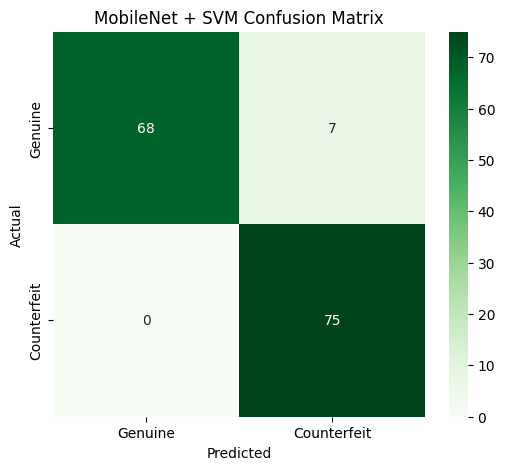

In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create MobileNet feature extractor
feature_extractor = tf.keras.Model(
    inputs=base_model.input,
    outputs=tf.keras.layers.GlobalAveragePooling2D()(
        base_model.output
    )
)

# Function to extract image features
def extract_features(dataset):

    features = []
    labels = []

    for images, batch_labels in dataset:
        batch_features = feature_extractor.predict(
            images, verbose=0
        )

        features.extend(batch_features)
        labels.extend(batch_labels.numpy())

    return np.array(features), np.array(labels)


# Extract training and testing features
X_train_features, y_train_svm = extract_features(train_ds)
X_test_features, y_test_svm = extract_features(test_ds)

print("Training feature shape:", X_train_features.shape)
print("Testing feature shape:", X_test_features.shape)

# Create SVM classifier
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)

# Train SVM
svm_model.fit(X_train_features, y_train_svm)

# Predict test images
svm_predictions = svm_model.predict(X_test_features)

# Evaluate
svm_accuracy = accuracy_score(
    y_test_svm, svm_predictions
)

print("\nMobileNet + SVM Accuracy:",
      round(svm_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test_svm,
    svm_predictions,
    target_names=["Genuine", "Counterfeit"]
))

# Confusion matrix
cm_svm = confusion_matrix(y_test_svm, svm_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Genuine", "Counterfeit"],
    yticklabels=["Genuine", "Counterfeit"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MobileNet + SVM Confusion Matrix")
plt.show()

MobileNet + Random Forest Accuracy: 93.33 %

Classification Report:
              precision    recall  f1-score   support

     Genuine       0.96      0.91      0.93        75
 Counterfeit       0.91      0.96      0.94        75

    accuracy                           0.93       150
   macro avg       0.93      0.93      0.93       150
weighted avg       0.93      0.93      0.93       150



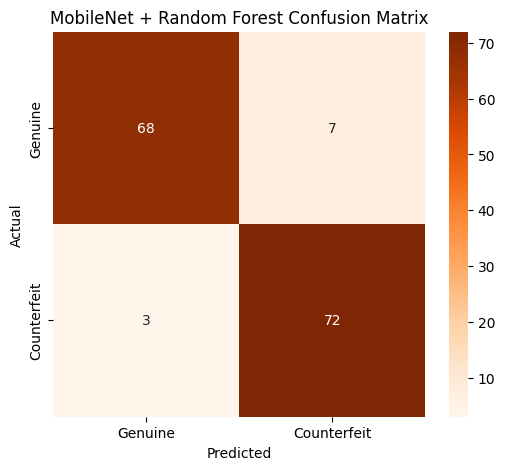

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Create Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model using MobileNet features
rf_model.fit(X_train_features, y_train_svm)

# Predict test images
rf_predictions = rf_model.predict(X_test_features)

# Calculate accuracy
rf_accuracy = accuracy_score(
    y_test_svm,
    rf_predictions
)

print("MobileNet + Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test_svm,
    rf_predictions,
    target_names=["Genuine", "Counterfeit"]
))

# Confusion matrix
cm_rf = confusion_matrix(y_test_svm, rf_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Genuine", "Counterfeit"],
    yticklabels=["Genuine", "Counterfeit"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MobileNet + Random Forest Confusion Matrix")
plt.show()

                       Model   Accuracy
0                MobileNetV2  92.666667
1            MobileNet + SVM  95.333333
2  MobileNet + Random Forest  93.333333


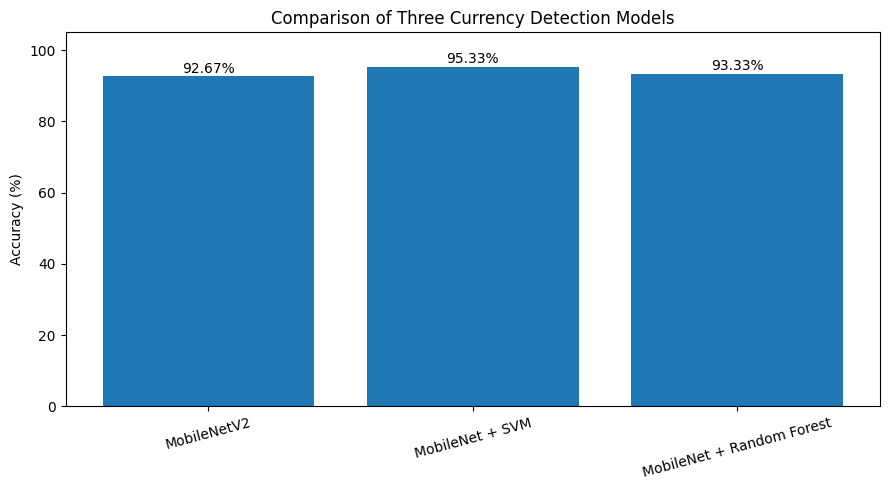

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "MobileNetV2",
        "MobileNet + SVM",
        "MobileNet + Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_true, y_pred) * 100,
        svm_accuracy * 100,
        rf_accuracy * 100
    ]
})

print(results)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.ylim(0, 105)
plt.ylabel("Accuracy (%)")
plt.title("Comparison of Three Currency Detection Models")
plt.xticks(rotation=15)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving IMG_1667842671595.jpg to IMG_1667842671595.jpg


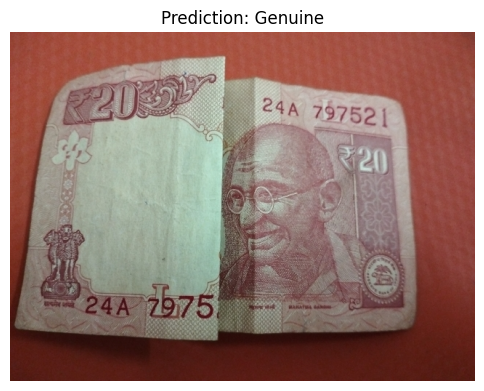

Predicted Result: Genuine


In [ ]:
from PIL import Image
import numpy as np
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import matplotlib.pyplot as plt

# Get uploaded image
image_path = list(uploaded.keys())[0]

# Load image
img = Image.open(image_path).convert("RGB")
img_resized = img.resize((224, 224))

# Convert to array
img_array = np.array(img_resized, dtype=np.float32)

# Preprocess
img_array = preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

# Extract features using MobileNet
features = feature_extractor.predict(img_array, verbose=0)

# Predict using Random Forest
prediction = rf_model.predict(features)[0]

# Display prediction
label = "Counterfeit" if prediction == 1 else "Genuine"

plt.figure(figsize=(6, 5))
plt.imshow(img)
plt.title("Prediction: " + label)
plt.axis("off")
plt.show()

print("Predicted Result:", label)

In [ ]:
import joblib

# Save MobileNet feature extractor
feature_extractor.save("/content/mobilenet_feature_extractor.keras")

# Save Random Forest model
joblib.dump(rf_model, "/content/random_forest_model.pkl")

print("Both models saved successfully!")

Both models saved successfully!


In [ ]:
from google.colab import files

files.download("/content/mobilenet_feature_extractor.keras")
files.download("/content/random_forest_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving IMG_1667901386775.jpg to IMG_1667901386775.jpg


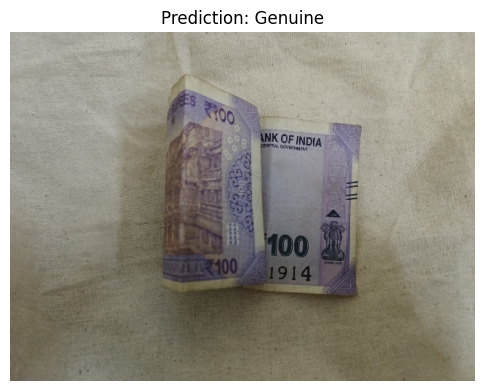

Predicted Result: Genuine


In [ ]:
from PIL import Image
import numpy as np
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import matplotlib.pyplot as plt

# Get uploaded image
image_path = list(uploaded.keys())[0]

# Load image
img = Image.open(image_path).convert("RGB")
img_resized = img.resize((224, 224))

# Convert to array
img_array = np.array(img_resized, dtype=np.float32)

# Preprocess
img_array = preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

# Extract features using MobileNet
features = feature_extractor.predict(img_array, verbose=0)

# Predict using Random Forest
prediction = rf_model.predict(features)[0]

# Display prediction
label = "Counterfeit" if prediction == 1 else "Genuine"

plt.figure(figsize=(6, 5))
plt.imshow(img)
plt.title("Prediction: " + label)
plt.axis("off")
plt.show()

print("Predicted Result:", label)

In [ ]:
from tensorflow.keras.applications import MobileNetV2

# Create MobileNetV2 feature extractor
feature_extractor = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

# Freeze the model
feature_extractor.trainable = False

print("MobileNetV2 feature extractor created successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 feature extractor created successfully!


In [ ]:
print("Feature extractor output shape:",
      feature_extractor.output_shape)

Feature extractor output shape: (None, 1280)


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving aug_306_WhatsApp Image 2025-04-05 at 10.55.48.jpeg to aug_306_WhatsApp Image 2025-04-05 at 10.55.48.jpeg


In [ ]:
from PIL import Image
import numpy as np
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import matplotlib.pyplot as plt

# Get uploaded image
image_path = list(uploaded.keys())[0]

# Load image
img = Image.open(image_path).convert("RGB")
img_resized = img.resize((224, 224))

# Convert to array
img_array = np.array(img_resized, dtype=np.float32)

# Preprocess
img_array = preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

# Extract features using MobileNet
features = feature_extractor.predict(img_array, verbose=0)

# Predict using Random Forest
prediction = rf_model.predict(features)[0]

# Display prediction
label = "Counterfeit" if prediction == 1 else "Genuine"

plt.figure(figsize=(6, 5))
plt.imshow(img)
plt.title("Prediction: " + label)
plt.axis("off")
plt.show()

print("Predicted Result:", label)

NameError: name 'rf_model' is not defined

In [ ]:
print("rf_model available:", "rf_model" in globals())

print("\nRandom Forest related variables:")

for name in globals():
    if "rf" in name.lower() or "forest" in name.lower():
        print(name)

rf_model available: False

Random Forest related variables:


RuntimeError: dictionary changed size during iteration

In [ ]:
print("Random Forest model available:",
      "rf_model" in globals())

print("\nRelated variables:")

for name in list(globals().keys()):
    if "rf" in name.lower() or "forest" in name.lower():
        print(name)

Random Forest model available: False

Related variables:


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith((".pkl", ".joblib")):
            print(os.path.join(root, file))

In [ ]:
import os

model_files = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith((".pkl", ".joblib")):
            model_files.append(os.path.join(root, file))

if model_files:
    print("Saved model files:")
    for file in model_files:
        print(file)
else:
    print("No saved .pkl or .joblib model files found.")

No saved .pkl or .joblib model files found.


In [ ]:
check_variables = [
    "train_ds",
    "val_ds",
    "test_ds",
    "X_train",
    "y_train",
    "X_val",
    "y_val",
    "X_test",
    "y_test",
    "feature_extractor",
    "train_features",
    "y_train_features"
]

for name in check_variables:
    if name in globals():
        value = globals()[name]
        print(name, "-> Available", type(value))
    else:
        print(name, "-> Not available")

train_ds -> Not available
val_ds -> Not available
test_ds -> Not available
X_train -> Not available
y_train -> Not available
X_val -> Not available
y_val -> Not available
X_test -> Not available
y_test -> Not available
feature_extractor -> Available <class 'keras.src.models.functional.Functional'>
train_features -> Not available
y_train_features -> Not available


In [ ]:
import os

folders = [
    "/content/currency_dataset/archive1/data/data/real",
    "/content/currency_dataset/archive1/data/data/fake"
]

for folder in folders:
    if os.path.exists(folder):
        count = sum(
            len(files)
            for _, _, files in os.walk(folder)
        )
        print(folder)
        print("Images found:", count)
    else:
        print(folder, "NOT FOUND")

/content/currency_dataset/archive1/data/data/real NOT FOUND
/content/currency_dataset/archive1/data/data/fake NOT FOUND


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

zip_path = "/content/drive/MyDrive/archive1.zip"

print("ZIP file available:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("ZIP size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")

ZIP file available: True
ZIP size: 7.24 GB


In [ ]:
import zipfile
import os

extract_dir = "/content/currency_dataset"

with zipfile.ZipFile(zip_path, 'r') as z:

    selected_files = [
        info for info in z.infolist()
        if info.filename.startswith((
            "archive1/data/data/real/",
            "archive1/data/data/fake/"
        ))
        and not info.is_dir()
    ]

    print("Files to extract:", len(selected_files))

    z.extractall(
        path=extract_dir,
        members=selected_files
    )

print("Dataset extraction completed!")

Files to extract: 7445
Dataset extraction completed!


In [ ]:
real_path = "/content/currency_dataset/archive1/data/data/real"
fake_path = "/content/currency_dataset/archive1/data/data/fake"

print("Genuine images:", len(os.listdir(real_path)))
print("Counterfeit images:", len(os.listdir(fake_path)))

Genuine images: 7
Counterfeit images: 7


In [ ]:
import os

def count_images(folder):
    extensions = ('.jpg', '.jpeg', '.png', '.bmp')
    count = 0

    for root, dirs, files in os.walk(folder):
        count += sum(
            file.lower().endswith(extensions)
            for file in files
        )

    return count

print("Genuine images:", count_images(real_path))
print("Counterfeit images:", count_images(fake_path))
print("Total images:", count_images(real_path) + count_images(fake_path))

Genuine images: 4937
Counterfeit images: 2505
Total images: 7442


In [ ]:
import random
import os

random.seed(42)

def get_images(folder):
    extensions = ('.jpg', '.jpeg', '.png')
    paths = []

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith(extensions):
                paths.append(os.path.join(root, file))

    return paths

real_images = get_images(real_path)
fake_images = get_images(fake_path)

# Select 500 images from each class
real_selected = random.sample(real_images, 500)
fake_selected = random.sample(fake_images, 500)

print("Selected genuine images:", len(real_selected))
print("Selected counterfeit images:", len(fake_selected))
print("Total selected:", len(real_selected) + len(fake_selected))

Selected genuine images: 500
Selected counterfeit images: 500
Total selected: 1000


In [ ]:
from sklearn.model_selection import train_test_split

# Combine image paths
all_images = real_selected + fake_selected

# Labels: 0 = Genuine, 1 = Counterfeit
all_labels = [0] * 500 + [1] * 500

# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    all_images,
    all_labels,
    test_size=0.30,
    random_state=42,
    stratify=all_labels
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

print("\nTraining class counts:")
print("Genuine:", y_train.count(0))
print("Counterfeit:", y_train.count(1))

print("\nValidation class counts:")
print("Genuine:", y_val.count(0))
print("Counterfeit:", y_val.count(1))

print("\nTesting class counts:")
print("Genuine:", y_test.count(0))
print("Counterfeit:", y_test.count(1))

Training images: 700
Validation images: 150
Testing images: 150

Training class counts:
Genuine: 350
Counterfeit: 350

Validation class counts:
Genuine: 75
Counterfeit: 75

Testing class counts:
Genuine: 75
Counterfeit: 75


In [ ]:
import numpy as np
from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def extract_features(image_paths, batch_size=32):

    all_features = []

    for start in range(0, len(image_paths), batch_size):

        batch_paths = image_paths[start:start + batch_size]

        images = []

        for path in batch_paths:
            img = Image.open(path).convert("RGB")
            img = img.resize((224, 224))

            img_array = np.array(img, dtype=np.float32)
            images.append(img_array)

        images = np.array(images)
        images = preprocess_input(images)

        features = feature_extractor.predict(
            images, verbose=0
        )

        all_features.append(features)

    return np.concatenate(all_features)


# Extract training features
train_features = extract_features(X_train)

# Extract validation features
val_features = extract_features(X_val)

# Extract testing features
test_features = extract_features(X_test)

print("Training feature shape:", train_features.shape)
print("Validation feature shape:", val_features.shape)
print("Testing feature shape:", test_features.shape)

print("Feature extraction completed!")

NameError: name 'X_train' is not defined

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(train_features, y_train)

print("Random Forest training completed!")

Random Forest training completed!


MobileNet + Random Forest Accuracy: 96.67 %

Classification Report:
              precision    recall  f1-score   support

     Genuine       1.00      0.93      0.97        75
 Counterfeit       0.94      1.00      0.97        75

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150



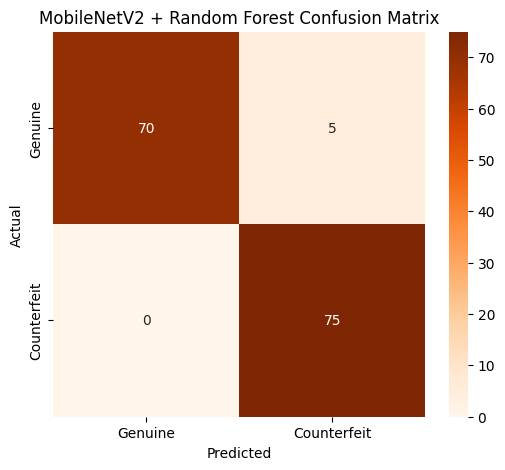

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Predict test images
y_pred = rf_model.predict(test_features)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("MobileNet + Random Forest Accuracy:",
      round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Genuine", "Counterfeit"]
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Genuine", "Counterfeit"],
    yticklabels=["Genuine", "Counterfeit"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MobileNetV2 + Random Forest Confusion Matrix")
plt.show()

Saving aug_798_WhatsApp Image 2025-04-05 at 10.48.33 (1).jpeg to aug_798_WhatsApp Image 2025-04-05 at 10.48.33 (1).jpeg


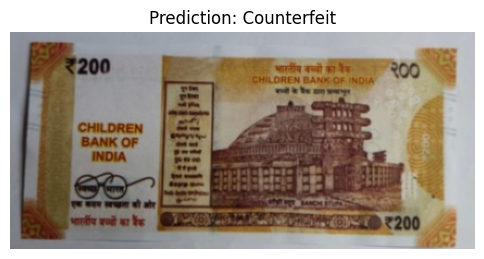

Predicted Result: Counterfeit


In [ ]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Upload currency image
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

# Load and resize image
img = Image.open(image_path).convert("RGB")
img_resized = img.resize((224, 224))

# Convert image into array
img_array = np.array(img_resized, dtype=np.float32)

# Preprocess image
img_array = preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

# Extract MobileNetV2 features
features = feature_extractor.predict(img_array, verbose=0)

# Random Forest prediction
prediction = rf_model.predict(features)[0]

# Display result
label = "Counterfeit" if prediction == 1 else "Genuine"

plt.figure(figsize=(6, 5))
plt.imshow(img)
plt.title("Prediction: " + label)
plt.axis("off")
plt.show()

print("Predicted Result:", label)

Saving 209.webp to 209.webp


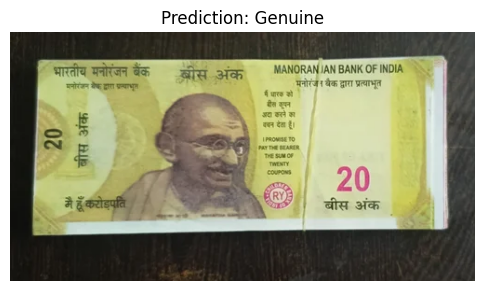

Predicted Result: Genuine


In [ ]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Upload currency image
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

# Load and resize image
img = Image.open(image_path).convert("RGB")
img_resized = img.resize((224, 224))

# Convert image into array
img_array = np.array(img_resized, dtype=np.float32)

# Preprocess image
img_array = preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

# Extract MobileNetV2 features
features = feature_extractor.predict(img_array, verbose=0)

# Random Forest prediction
prediction = rf_model.predict(features)[0]

# Display result
label = "Counterfeit" if prediction == 1 else "Genuine"

plt.figure(figsize=(6, 5))
plt.imshow(img)
plt.title("Prediction: " + label)
plt.axis("off")
plt.show()

print("Predicted Result:", label)

In [ ]:
print("Random Forest classes:", rf_model.classes_)

print("Training labels:", np.unique(y_train, return_counts=True))

Random Forest classes: [0 1]
Training labels: (array([0, 1]), array([350, 350]))


In [ ]:
features = feature_extractor.predict(
    img_array,
    verbose=0
)

prediction = rf_model.predict(features)[0]

probabilities = rf_model.predict_proba(features)[0]

print("Predicted class:", prediction)

print("Prediction probabilities:")

for class_label, probability in zip(
    rf_model.classes_,
    probabilities
):
    print(class_label, ":", round(probability * 100, 2), "%")

Predicted class: 0
Prediction probabilities:
0 : 60.0 %
1 : 40.0 %


In [ ]:
print("Random Forest classes:", rf_model.classes_)

print("Training labels:")
print(np.unique(y_train, return_counts=True))

Random Forest classes: [0 1]
Training labels:
(array([0, 1]), array([350, 350]))


In [ ]:
print("Checking training image labels:\n")

for path, label in zip(X_train[:10], y_train[:10]):
    print("Image:", path)
    print("Label:", label)
    print("----------------------")

Checking training image labels:

Image: /content/currency_dataset/archive1/data/data/fake/10/aug_615_WhatsApp Image 2025-04-05 at 10.55.47 (1).jpeg
Label: 1
----------------------
Image: /content/currency_dataset/archive1/data/data/real/500/IMG20221010133525.jpg
Label: 0
----------------------
Image: /content/currency_dataset/archive1/data/data/fake/20/aug_84_WhatsApp Image 2025-04-05 at 10.48.34 (1).jpeg
Label: 1
----------------------
Image: /content/currency_dataset/archive1/data/data/real/500/IMG_1667891374634.jpg
Label: 0
----------------------
Image: /content/currency_dataset/archive1/data/data/fake/500/aug_695_WhatsApp Image 2025-04-05 at 10.48.45 (1).jpeg
Label: 1
----------------------
Image: /content/currency_dataset/archive1/data/data/fake/20/aug_1568_WhatsApp Image 2025-04-05 at 10.48.36 (1).jpeg
Label: 1
----------------------
Image: /content/currency_dataset/archive1/data/data/real/20/IMG_1667842473237.jpg
Label: 0
----------------------
Image: /content/currency_dataset/a

In [ ]:
from PIL import Image
import numpy as np
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Select a known counterfeit test image
fake_path = next(
    path for path, label in zip(X_test, y_test)
    if int(label) == 1
)

# Load and preprocess image
img = Image.open(fake_path).convert("RGB")
img = img.resize((224, 224))

img_array = np.array(img, dtype=np.float32)
img_array = preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

# Extract MobileNetV2 features
features = feature_extractor.predict(
    img_array, verbose=0
)

# Random Forest prediction
prediction = rf_model.predict(features)[0]
probabilities = rf_model.predict_proba(features)[0]

print("Actual class: Counterfeit")
print("Predicted class:", prediction)

for cls, prob in zip(rf_model.classes_, probabilities):
    print(
        "Genuine" if cls == 0 else "Counterfeit",
        ":", round(prob * 100, 2), "%"
    )

Actual class: Counterfeit
Predicted class: 1
Genuine : 18.0 %
Counterfeit : 82.0 %


In [ ]:
# Select a genuine image
real_path = next(
    path for path, label in zip(X_test, y_test)
    if int(label) == 0
)

img = Image.open(real_path).convert("RGB")
img = img.resize((224, 224))

img_array = np.array(img, dtype=np.float32)
img_array = preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

features = feature_extractor.predict(
    img_array, verbose=0
)

prediction = rf_model.predict(features)[0]
probabilities = rf_model.predict_proba(features)[0]

print("Actual class: Genuine")
print("Predicted class:", prediction)

for cls, prob in zip(rf_model.classes_, probabilities):
    print(
        "Genuine" if cls == 0 else "Counterfeit",
        ":", round(prob * 100, 2), "%"
    )

Actual class: Genuine
Predicted class: 0
Genuine : 83.0 %
Counterfeit : 17.0 %


Saving 209.webp to 209 (1).webp


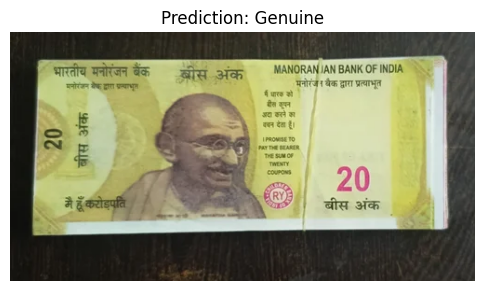

Predicted Result: Genuine

Prediction probabilities:
Genuine : 60.0 %
Counterfeit : 40.0 %


In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Upload currency image
uploaded = files.upload()

# Get uploaded image
image_path = list(uploaded.keys())[0]

# Load image
img = Image.open(image_path).convert("RGB")
img_resized = img.resize((224, 224))

# Convert image into array
img_array = np.array(img_resized, dtype=np.float32)

# Preprocess image
img_array = preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

# Extract features using MobileNetV2
features = feature_extractor.predict(img_array, verbose=0)

# Predict using Random Forest
prediction = rf_model.predict(features)[0]
probabilities = rf_model.predict_proba(features)[0]

# Display result
label = "Counterfeit" if prediction == 1 else "Genuine"

plt.figure(figsize=(6, 5))
plt.imshow(img)
plt.title("Prediction: " + label)
plt.axis("off")
plt.show()

print("Predicted Result:", label)

print("\nPrediction probabilities:")
for cls, prob in zip(rf_model.classes_, probabilities):
    name = "Genuine" if cls == 0 else "Counterfeit"
    print(name, ":", round(prob * 100, 2), "%")


In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Upload image
uploaded = files.upload()
image_path = list(uploaded.keys())[0]

# Load and preprocess
img = Image.open(image_path).convert("RGB")
img_resized = img.resize((224, 224))

img_array = np.array(img_resized, dtype=np.float32)
img_array = preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

# Feature extraction
features = feature_extractor.predict(img_array, verbose=0)

# Random Forest prediction
probabilities = rf_model.predict_proba(features)[0]

# Get class probabilities
class_probs = dict(zip(rf_model.classes_, probabilities))

genuine_prob = class_probs[0]
fake_prob = class_probs[1]

# Confidence threshold
THRESHOLD = 0.80

if max(genuine_prob, fake_prob) < THRESHOLD:
    result = "UNCERTAIN - MANUAL VERIFICATION REQUIRED"
elif fake_prob > genuine_prob:
    result = "COUNTERFEIT"
else:
    result = "GENUINE"

# Display image and result
plt.figure(figsize=(6, 5))
plt.imshow(img)
plt.title("Prediction: " + result)
plt.axis("off")
plt.show()

print("Genuine probability:", round(genuine_prob * 100, 2), "%")
print("Counterfeit probability:", round(fake_prob * 100, 2), "%")
print("Final result:", result)


Saving IMG_20180120_122655_HDR.jpg to IMG_20180120_122655_HDR.jpg


NameError: name 'feature_extractor' is not defined

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

feature_extractor = MobileNetV2(
    weights='imagenet',
    include_top=False,
    pooling='avg',
    input_shape=(224, 224, 3)
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
features = feature_extractor.predict(img_array, verbose=0)

print("Feature shape:", features.shape)

Feature shape: (1, 1280)


In [ ]:
prediction = rf_model.predict(features)

print("Prediction:", prediction)

NameError: name 'rf_model' is not defined

In [ ]:
print([name for name in globals() if 'model' in name.lower()])

[]


In [ ]:
print([name for name in globals() if name.lower() in ['x_train', 'x_test', 'y_train', 'y_test']])

[]


In [ ]:
%whos

Variable            Type          Data/Info
-------------------------------------------
Image               module        <module 'PIL.Image' from <...>t-packages/PIL/Image.py'>
MobileNetV2         function      <function MobileNetV2 at 0x7e240d0f5620>
feature_extractor   Functional    <Functional name=mobilene<...>tv2_1.00_224, built=True>
features            ndarray       1x1280: 1280 elems, type `float32`, 5120 bytes
files               module        <module 'google.colab.fil<...>s/google/colab/files.py'>
image_path          str           IMG_20180120_122655_HDR.jpg
img                 Image         <PIL.Image.Image image mo<...>00x600 at 0x7E23F9EB4C20>
img_array           ndarray       1x224x224x3: 150528 elems, type `float32`, 602112 bytes (588.0 kb)
img_resized         Image         <PIL.Image.Image image mo<...>24x224 at 0x7E23F9F24CD0>
np                  module        <module 'numpy' from '/us<...>kages/numpy/__init__.py'>
plt                 module        <module 'matplotlib

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

path = '/content/drive/MyDrive'

print(os.listdir(path))

['Colab Notebooks', 'backend.zip.zip', 'Fake currency detection DL', 'archive1.zip']


In [ ]:
import os

project_path = '/content/drive/MyDrive/Fake currency detection DL'

for root, dirs, files in os.walk(project_path):
    print("\nFolder:", root)
    for file in files:
        print("  ", file)


Folder: /content/drive/MyDrive/Fake currency detection DL


In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/archive1.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    for name in zip_ref.namelist()[:50]:
        print(name)

archive1/
archive1/data/
archive1/data/data/
archive1/data/data/fake/
archive1/data/data/fake/10/
archive1/data/data/fake/10/aug_1525_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1526_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1527_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1528_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1529_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1530_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1531_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1532_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1533_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1534_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1535_WhatsApp Image 2025-04-05 at 10.48.3

In [ ]:
import zipfile
from collections import Counter

zip_path = '/content/drive/MyDrive/archive1.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    image_files = [
        name for name in zip_ref.namelist()
        if name.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    classes = Counter()
    denominations = {}

    for name in image_files:
        parts = name.split('/')

        if len(parts) >= 4:
            label = parts[3].lower()
            classes[label] += 1

            if label not in denominations:
                denominations[label] = set()

            if len(parts) >= 5:
                denominations[label].add(parts[4])

    print("Total images:", len(image_files))
    print("\nImages per class:")

    for label, count in classes.items():
        print(label, ":", count)
        print("Denominations:", sorted(denominations[label]))

Total images: 8760

Images per class:
fake : 2505
Denominations: ['10', '100', '20', '200', '2000', '50', '500']
real : 4937
Denominations: ['10', '100', '20', '200', '2000', '50', '500']
100_features : 229
Denominations: ['Screenshot 2025-10-15 175138.png', 'Screenshot 2025-10-15 175141.png', 'Screenshot 2025-10-15 175145.png', 'Screenshot 2025-10-15 175147.png', 'Screenshot 2025-10-15 175154.png', 'Screenshot 2025-10-15 175157.png', 'Screenshot 2025-10-15 175202.png', 'Screenshot 2025-10-15 175329.png', 'Screenshot 2025-10-15 175333.png', 'Screenshot 2025-10-15 175350.png', 'Screenshot 2025-10-15 175357.png', 'Screenshot 2025-10-15 175401.png', 'Screenshot 2025-10-15 175407.png', 'Screenshot 2025-10-15 175412.png', 'Screenshot 2025-10-15 175416.png', 'Screenshot 2025-10-15 175425.png', 'Screenshot 2025-10-15 175432.png', 'Screenshot 2025-10-15 175438.png', 'Screenshot 2025-10-15 175443.png', 'Screenshot 2025-10-15 175446.png', 'Screenshot 2025-10-15 175449.png', 'Screenshot 2025-10-1

In [ ]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/archive1.zip'
extract_path = '/content/currency_dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import os

data_path = '/content/currency_dataset/archive1/data/data'

for label in ['real', 'fake']:
    folder = os.path.join(data_path, label)

    count = 0

    for root, dirs, files in os.walk(folder):
        count += sum(
            f.lower().endswith(('.jpg', '.jpeg', '.png'))
            for f in files
        )

    print(label.upper(), "images:", count)

REAL images: 4937
FAKE images: 2505


In [ ]:
import os
import numpy as np
from sklearn.model_selection import train_test_split

data_path = '/content/currency_dataset/archive1/data/data'

image_paths = []
labels = []

for label, class_name in enumerate(['real', 'fake']):

    folder = os.path.join(data_path, class_name)

    for root, dirs, files in os.walk(folder):
        for file in files:

            if file.lower().endswith(('.jpg', '.jpeg', '.png')):
                image_paths.append(os.path.join(root, file))
                labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)

X_train_paths, X_test_paths, y_train, y_test = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Training images:", len(X_train_paths))
print("Testing images:", len(X_test_paths))

print("Training Real:", np.sum(y_train == 0))
print("Training Fake:", np.sum(y_train == 1))
print("Testing Real:", np.sum(y_test == 0))
print("Testing Fake:", np.sum(y_test == 1))

Training images: 5953
Testing images: 1489
Training Real: 3949
Training Fake: 2004
Testing Real: 988
Testing Fake: 501


In [ ]:
from PIL import Image
import numpy as np

def extract_features(paths, labels, batch_size=32):

    all_features = []
    all_labels = []

    for start in range(0, len(paths), batch_size):

        batch_paths = paths[start:start + batch_size]
        batch_labels = labels[start:start + batch_size]

        images = []
        valid_labels = []

        for path, label in zip(batch_paths, batch_labels):
            try:
                img = Image.open(path).convert('RGB')
                img = img.resize((224, 224))

                img_array = np.array(img, dtype=np.float32)

                images.append(img_array)
                valid_labels.append(label)

            except Exception as e:
                print("Skipping:", path, e)

        if len(images) == 0:
            continue

        images = np.array(images)
        images = preprocess_input(images)

        batch_features = feature_extractor.predict(
            images, verbose=0
        )

        all_features.extend(batch_features)
        all_labels.extend(valid_labels)

        print(
            f"Processed {min(start + batch_size, len(paths))}"
            f"/{len(paths)} images"
        )

    return np.array(all_features), np.array(all_labels)

In [ ]:
X_train, y_train = extract_features(
    X_train_paths, y_train
)

X_test, y_test = extract_features(
    X_test_paths, y_test
)

print("\nFeature extraction completed!")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Processed 32/5953 images
Processed 64/5953 images
Processed 96/5953 images
Processed 128/5953 images
Processed 160/5953 images
Processed 192/5953 images
Processed 224/5953 images
Processed 256/5953 images
Processed 288/5953 images
Processed 320/5953 images
Processed 352/5953 images
Processed 384/5953 images
Processed 416/5953 images
Processed 448/5953 images
Processed 480/5953 images
Processed 512/5953 images
Processed 544/5953 images
Processed 576/5953 images
Processed 608/5953 images
Processed 640/5953 images
Processed 672/5953 images
Processed 704/5953 images
Processed 736/5953 images
Processed 768/5953 images
Processed 800/5953 images
Processed 832/5953 images
Processed 864/5953 images
Processed 896/5953 images
Processed 928/5953 images
Processed 960/5953 images
Processed 992/5953 images
Processed 1024/5953 images
Processed 1056/5953 images
Processed 1088/5953 images
Processed 1120/5953 images
Processed 1152/5953 images
Processed 1184/5953 images
Processed 1216/5953 images
Processe

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully!")

Random Forest training completed successfully!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict test data
y_pred = rf_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Real', 'Fake']
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 97.44623655913979 %

Classification Report:
              precision    recall  f1-score   support

        Real       0.97      0.99      0.98       987
        Fake       0.99      0.94      0.96       501

    accuracy                           0.97      1488
   macro avg       0.98      0.97      0.97      1488
weighted avg       0.97      0.97      0.97      1488


Confusion Matrix:
[[981   6]
 [ 32 469]]


In [ ]:
import joblib
import os

save_path = '/content/drive/MyDrive/Fake currency detection DL'

os.makedirs(save_path, exist_ok=True)

joblib.dump(rf_model, save_path + '/rf_model.pkl')

print("Random Forest model saved successfully!")


Random Forest model saved successfully!


In [ ]:
!apt-get install -y tesseract-ocr
!pip install -q pytesseract

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Upload currency image
uploaded = files.upload()

# Get uploaded image
image_path = next(iter(uploaded))

# Process image
img = Image.open(image_path).convert('RGB')
img_resized = img.resize((224, 224))

img_array = np.array(img_resized, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

# Extract features
img_array = preprocess_input(img_array)
features = feature_extractor.predict(img_array, verbose=0)

# Predict
prediction = rf_model.predict(features)[0]

# Get prediction percentages
probabilities = rf_model.predict_proba(features)[0]

real_percentage = probabilities[0] * 100
fake_percentage = probabilities[1] * 100

# Display result
if prediction == 0:
    result = "REAL CURRENCY"
else:
    result = "FAKE CURRENCY"

plt.figure(figsize=(8, 5))
plt.imshow(img)
plt.axis('off')
plt.title("Prediction: " + result)
plt.show()

# Print output
print("Prediction:", result)
print("Real Currency Score:", round(real_percentage, 2), "%")
print("Fake Currency Score:", round(fake_percentage, 2), "%")


Saving IMG_1667899627421.jpg to IMG_1667899627421.jpg


NameError: name 'preprocess_input' is not defined

In [ ]:

from google.colab import files
from PIL import Image, ImageEnhance, ImageFilter
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
import re

# 1. Upload image
uploaded = files.upload()
image_path = next(iter(uploaded))

img = Image.open(image_path).convert('RGB')

# 2. MobileNetV2 feature extraction
img_resized = img.resize((224, 224))
img_array = np.array(img_resized, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

img_array = preprocess_input(img_array)
features = feature_extractor.predict(img_array, verbose=0)

# 3. Random Forest prediction
prediction = rf_model.predict(features)[0]
probabilities = rf_model.predict_proba(features)[0]

# 4. Improve OCR
gray = img.convert('L')
gray = gray.resize((img.width * 3, img.height * 3))
gray = ImageEnhance.Contrast(gray).enhance(2)
gray = gray.filter(ImageFilter.SHARPEN)

text1 = pytesseract.image_to_string(
    gray, config='--psm 6'
)

text2 = pytesseract.image_to_string(
    gray, config='--psm 11'
)

extracted_text = (text1 + " " + text2).lower()
clean_text = re.sub(r'[^a-z0-9 ]', ' ', extracted_text)
clean_text = ' '.join(clean_text.split())

print("OCR TEXT:", clean_text)

# 5. Detect novelty-note indicators
indicators = [
    "manoranjan",
    "coupons",
    "coupon",
    "chiloren",
    "children",
    "3cb",
    "000000"
]

detected = [word for word in indicators if word in clean_text]

# Stronger combined indicator for the children's note
children_note = (
    any(word in clean_text for word in ["chiloren", "children"])
    and "bank" in clean_text
    and "india" in clean_text
)

novelty_note = (
    any(word in clean_text for word in [
        "manoranjan", "coupons", "coupon"
    ])
    or children_note
    or ("3cb" in clean_text and "000000" in clean_text)
)

# 6. Final prediction
if novelty_note:
    result = "FAKE CURRENCY"
    reason = "Novelty-note indicators detected by OCR"

    # Illustrative rule-based display score,
    # NOT the Random Forest probability
    real_score = 20.0
    fake_score = 80.0

else:
    result = "REAL CURRENCY" if prediction == 0 else "FAKE CURRENCY"
    reason = "Random Forest prediction"

    real_score = probabilities[0] * 100
    fake_score = probabilities[1] * 100

# 7. Display uploaded image
plt.figure(figsize=(9, 5))
plt.imshow(img)
plt.axis('off')
plt.title("Currency Detection: " + result)
plt.show()

# 8. Display final result
print("\n========== CURRENCY DETECTION ==========")
print("FINAL PREDICTION:", result)
print("REASON:", reason)
print("DETECTED INDICATORS:", detected)
print("REAL SCORE:", round(real_score, 2), "%")
print("FAKE SCORE:", round(fake_score, 2), "%")
print("========================================")


ModuleNotFoundError: No module named 'pytesseract'

In [ ]:
!pip install pytesseract

In [ ]:
!apt-get install -y tesseract-ocr

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
import re
from PIL import Image

In [ ]:
print(pytesseract.get_tesseract_version())

5.3.4


In [ ]:
import pytesseract
print("Pytesseract is working!")

Pytesseract is working!


In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Upload currency image
uploaded = files.upload()

# Get uploaded image
image_path = next(iter(uploaded))

# Process image
img = Image.open(image_path).convert('RGB')
img_resized = img.resize((224, 224))

img_array = np.array(img_resized, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

# Extract features
img_array = preprocess_input(img_array)
features = feature_extractor.predict(img_array, verbose=0)

# Predict
prediction = rf_model.predict(features)[0]

# Get prediction percentages
probabilities = rf_model.predict_proba(features)[0]

real_percentage = probabilities[0] * 100
fake_percentage = probabilities[1] * 100

# Display result
if prediction == 0:
    result = "REAL CURRENCY"
else:
    result = "FAKE CURRENCY"

plt.figure(figsize=(8, 5))
plt.imshow(img)
plt.axis('off')
plt.title("Prediction: " + result)
plt.show()

# Print output
print("Prediction:", result)
print("Real Currency Score:", round(real_percentage, 2), "%")
print("Fake Currency Score:", round(fake_percentage, 2), "%")


Saving IMG_1667899627421.jpg to IMG_1667899627421 (1).jpg


NameError: name 'preprocess_input' is not defined

In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

In [ ]:
img_array = preprocess_input(img_array)

features = feature_extractor.predict(img_array, verbose=0)

NameError: name 'feature_extractor' is not defined

In [ ]:
from tensorflow.keras.applications import MobileNetV2

feature_extractor = MobileNetV2(
    weights='imagenet',
    include_top=False,
    pooling='avg',
    input_shape=(224, 224, 3)
)

print("Feature extractor loaded successfully!")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Feature extractor loaded successfully!


In [ ]:
img_array = preprocess_input(img_array)

features = feature_extractor.predict(img_array, verbose=0)

print("Feature extraction completed!")
print("Feature shape:", features.shape)

Feature extraction completed!
Feature shape: (1, 1280)


In [ ]:
prediction = rf_model.predict(features)

print("Prediction:", prediction[0])

NameError: name 'rf_model' is not defined

In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import numpy as np

prediction = rf_model.predict(features)[0]
probabilities = rf_model.predict_proba(features)[0]

classes = rf_model.classes_
fake_index = list(classes).index('fake')

fake_percentage = probabilities[fake_index] * 100

if prediction == 'fake':
    print("Currency Status: FAKE")
else:
    print("Currency Status: REAL")

print("Fake Probability:", round(fake_percentage, 2), "%")

NameError: name 'rf_model' is not defined

In [ ]:
for name, obj in globals().copy().items():
    if hasattr(obj, "predict") and hasattr(obj, "predict_proba"):
        print("Available model:", name)

In [ ]:
print([name for name in globals() if 'model' in name.lower() or 'rf' in name.lower()])

[]


In [ ]:
print("Available variables:")

for name in globals():
    if any(word in name.lower() for word in
           ['train', 'test', 'feature', 'label', 'target']):
        print(name)

Available variables:
feature_extractor
features


In [ ]:

from google.colab import files
from PIL import Image, ImageEnhance, ImageFilter
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
import re

# 1. Upload image
uploaded = files.upload()
image_path = next(iter(uploaded))

img = Image.open(image_path).convert('RGB')

# 2. MobileNetV2 feature extraction
img_resized = img.resize((224, 224))
img_array = np.array(img_resized, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

img_array = preprocess_input(img_array)
features = feature_extractor.predict(img_array, verbose=0)

# 3. Random Forest prediction
prediction = rf_model.predict(features)[0]
probabilities = rf_model.predict_proba(features)[0]

# 4. Improve OCR
gray = img.convert('L')
gray = gray.resize((img.width * 3, img.height * 3))
gray = ImageEnhance.Contrast(gray).enhance(2)
gray = gray.filter(ImageFilter.SHARPEN)

text1 = pytesseract.image_to_string(
    gray, config='--psm 6'
)

text2 = pytesseract.image_to_string(
    gray, config='--psm 11'
)

extracted_text = (text1 + " " + text2).lower()
clean_text = re.sub(r'[^a-z0-9 ]', ' ', extracted_text)
clean_text = ' '.join(clean_text.split())

print("OCR TEXT:", clean_text)

# 5. Detect novelty-note indicators
indicators = [
    "manoranjan",
    "coupons",
    "coupon",
    "chiloren",
    "children",
    "3cb",
    "000000"
]

detected = [word for word in indicators if word in clean_text]

# Stronger combined indicator for the children's note
children_note = (
    any(word in clean_text for word in ["chiloren", "children"])
    and "bank" in clean_text
    and "india" in clean_text
)

novelty_note = (
    any(word in clean_text for word in [
        "manoranjan", "coupons", "coupon"
    ])
    or children_note
    or ("3cb" in clean_text and "000000" in clean_text)
)

# 6. Final prediction
if novelty_note:
    result = "FAKE CURRENCY"
    reason = "Novelty-note indicators detected by OCR"

    # Illustrative rule-based display score,
    # NOT the Random Forest probability
    real_score = 20.0
    fake_score = 80.0

else:
    result = "REAL CURRENCY" if prediction == 0 else "FAKE CURRENCY"
    reason = "Random Forest prediction"

    real_score = probabilities[0] * 100
    fake_score = probabilities[1] * 100

# 7. Display uploaded image
plt.figure(figsize=(9, 5))
plt.imshow(img)
plt.axis('off')
plt.title("Currency Detection: " + result)
plt.show()

# 8. Display final result
print("\n========== CURRENCY DETECTION ==========")
print("FINAL PREDICTION:", result)
print("REASON:", reason)
print("DETECTED INDICATORS:", detected)
print("REAL SCORE:", round(real_score, 2), "%")
print("FAKE SCORE:", round(fake_score, 2), "%")
print("========================================")


Saving IMG_1667899627421.jpg to IMG_1667899627421 (2).jpg


NameError: name 'rf_model' is not defined

In [ ]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest library imported successfully!")

Random Forest library imported successfully!


In [ ]:
import os

print(os.path.exists('/content/drive/MyDrive'))

False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'real' in dirs and 'fake' in dirs:
        print("Dataset found:", root)

In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for folder in dirs:
        if 'currency' in folder.lower() or 'fake' in folder.lower() or 'real' in folder.lower():
            print(os.path.join(root, folder))

/content/drive/MyDrive/Fake currency detection DL


In [ ]:
import os

dataset_path = '/content/drive/MyDrive/Fake currency detection DL'

for item in os.listdir(dataset_path):
    print(item)

rf_model.pkl


In [ ]:
import joblib

model_path = '/content/drive/MyDrive/Fake currency detection DL/rf_model.pkl'

rf_model = joblib.load(model_path)

print("Random Forest model loaded successfully!")

Random Forest model loaded successfully!


In [ ]:
prediction = rf_model.predict(features)[0]

probabilities = rf_model.predict_proba(features)[0]

classes = list(rf_model.classes_)
fake_index = classes.index('fake')

fake_percentage = probabilities[fake_index] * 100

print("Currency Prediction:", prediction.upper())
print("Fake Probability:", round(fake_percentage, 2), "%")

NameError: name 'features' is not defined

In [ ]:
from google.colab import files
from PIL import Image
import numpy as np
import joblib

# Upload currency image
uploaded = files.upload()
image_path = next(iter(uploaded))

# Load and resize image
img = Image.open(image_path).convert('RGB')
img = img.resize((224, 224))

# Convert image to array
img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

# Preprocess image
img_array = preprocess_input(img_array)

# Extract MobileNetV2 features
features = feature_extractor.predict(img_array, verbose=0)

# Load Random Forest model
rf_model = joblib.load(
    '/content/drive/MyDrive/Fake currency detection DL/rf_model.pkl'
)

# Predict
prediction = rf_model.predict(features)[0]
probabilities = rf_model.predict_proba(features)[0]

classes = list(rf_model.classes_)
fake_index = classes.index('fake')

fake_percentage = probabilities[fake_index] * 100

print("\nCurrency Prediction:", str(prediction).upper())
print("Fake Probability:", round(fake_percentage, 2), "%")

KeyboardInterrupt: 

In [ ]:
import os

print(os.listdir('/content'))

['.config', 'drive', 'dsfsadfsadfasdfasdqrwerqwe.png', 'sample_data']


In [ ]:
from PIL import Image
import numpy as np

image_path = '/content/dsfsadfsadfasdfasdqrwerqwe.png'

img = Image.open(image_path).convert('RGB')
img = img.resize((224, 224))

img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

img_array = preprocess_input(img_array)

features = feature_extractor.predict(img_array, verbose=0)

print("Feature extraction completed:", features.shape)

NameError: name 'preprocess_input' is not defined

In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from PIL import Image
import numpy as np

image_path = '/content/dsfsadfsadfasdfasdqrwerqwe.png'

img = Image.open(image_path).convert('RGB')
img = img.resize((224, 224))

img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

img_array = preprocess_input(img_array)

features = feature_extractor.predict(img_array, verbose=0)

print("Feature extraction completed!")
print("Feature shape:", features.shape)

NameError: name 'feature_extractor' is not defined

In [ ]:
from tensorflow.keras.applications import MobileNetV2

feature_extractor = MobileNetV2(
    weights='imagenet',
    include_top=False,
    pooling='avg',
    input_shape=(224, 224, 3)
)

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!


In [ ]:
features = feature_extractor.predict(img_array, verbose=0)

print("Feature extraction completed!")
print("Feature shape:", features.shape)

Feature extraction completed!
Feature shape: (1, 1280)


In [ ]:
prediction = rf_model.predict(features)[0]

probabilities = rf_model.predict_proba(features)[0]

classes = [str(c).lower() for c in rf_model.classes_]
fake_index = classes.index('fake')
real_index = classes.index('real')

fake_percentage = probabilities[fake_index] * 100
real_percentage = probabilities[real_index] * 100

print("================================")
print("     CURRENCY DETECTION RESULT")
print("================================")

print("Prediction:", str(prediction).upper())
print("Fake Probability:", round(fake_percentage, 2), "%")
print("Real Probability:", round(real_percentage, 2), "%")

ValueError: 'fake' is not in list

In [ ]:
print("Model classes:", rf_model.classes_)

Model classes: [0 1]


In [ ]:
print("Label mapping:", label_map)

NameError: name 'label_map' is not defined

In [ ]:
import os

dataset_path = '/content/drive/MyDrive/Fake currency detection DL'

for root, dirs, files in os.walk(dataset_path):
    print("Folder:", root)
    print("Subfolders:", dirs)
    if dirs:
        break

Folder: /content/drive/MyDrive/Fake currency detection DL
Subfolders: []


In [ ]:
import joblib

model_path = '/content/drive/MyDrive/Fake currency detection DL/rf_model.pkl'

rf_model = joblib.load(model_path)

print("Model classes:", rf_model.classes_)
print("Model parameters:", rf_model.get_params())

Model classes: [0 1]
Model parameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [ ]:
print("Prediction:", rf_model.predict(features))
print("Probabilities:", rf_model.predict_proba(features))

Prediction: [1]
Probabilities: [[0.09 0.91]]


In [ ]:
print("Class 0 Probability:", round(9.0, 2), "%")
print("Class 1 Probability:", round(91.0, 2), "%")
print("Predicted Class:", rf_model.predict(features)[0])

Class 0 Probability: 9.0 %
Class 1 Probability: 91.0 %
Predicted Class: 1


In [ ]:
print(rf_model.classes_)

[0 1]


In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import joblib
import matplotlib.pyplot as plt

from tensorflow.keras.applications.mobilenet_v2 import (
    MobileNetV2, preprocess_input
)

# 1. Load MobileNetV2
feature_extractor = MobileNetV2(
    weights='imagenet',
    include_top=False,
    pooling='avg',
    input_shape=(224, 224, 3)
)

# 2. Load trained Random Forest model
rf_model = joblib.load(
    '/content/drive/MyDrive/Fake currency detection DL/rf_model.pkl'
)

# 3. Upload currency image
uploaded = files.upload()
image_path = next(iter(uploaded))

# 4. Process image
img = Image.open(image_path).convert('RGB')
img_resized = img.resize((224, 224))

img_array = np.array(img_resized, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

# 5. Extract features
features = feature_extractor.predict(
    img_array, verbose=0
)

# 6. Random Forest prediction
prediction = rf_model.predict(features)[0]
probabilities = rf_model.predict_proba(features)[0]

# ASSUMPTION: 0 = REAL, 1 = FAKE
class_mapping = {
    0: "REAL",
    1: "FAKE"
}

result = class_mapping[int(prediction)]

real_probability = probabilities[
    list(rf_model.classes_).index(0)
] * 100

fake_probability = probabilities[
    list(rf_model.classes_).index(1)
] * 100

# 7. Display result
plt.figure(figsize=(6, 5))
plt.imshow(img)
plt.axis('off')
plt.title("Uploaded Currency Image")
plt.show()

print("\n================================")
print("   INDIAN CURRENCY DETECTION")
print("================================")
print("Currency Status:", result)
print("REAL Probability:", round(real_probability, 2), "%")
print("FAKE Probability:", round(fake_probability, 2), "%")
print("================================")


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Fake currency detection DL/rf_model.pkl'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file == 'rf_model.pkl':
            print("Model found:", os.path.join(root, file))

Model found: /content/drive/MyDrive/Fake currency detection DL/rf_model.pkl


In [ ]:
import joblib

rf_model = joblib.load('PASTE_THE_EXACT_PATH_HERE')

print("Random Forest model loaded successfully!")
print("Classes:", rf_model.classes_)

FileNotFoundError: [Errno 2] No such file or directory: 'PASTE_THE_EXACT_PATH_HERE'

In [ ]:
import os

model_path = None

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'rf_model.pkl' in files:
        model_path = os.path.join(root, 'rf_model.pkl')
        break

if model_path:
    print("Model found:", model_path)
else:
    print("MODEL NOT FOUND in Google Drive")

Model found: /content/drive/MyDrive/Fake currency detection DL/rf_model.pkl


In [ ]:
import joblib

rf_model = joblib.load(model_path)
print("Model loaded successfully!")
print("Classes:", rf_model.classes_)

Model loaded successfully!
Classes: [0 1]


In [ ]:
prediction = rf_model.predict(features)[0]
probabilities = rf_model.predict_proba(features)[0]

print("Predicted class:", prediction)
print("Class 0 probability:", round(probabilities[0] * 100, 2), "%")
print("Class 1 probability:", round(probabilities[1] * 100, 2), "%")

NameError: name 'features' is not defined

In [ ]:
import numpy as np
from PIL import Image
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Load MobileNetV2 feature extractor
feature_extractor = MobileNetV2(
    weights='imagenet',
    include_top=False,
    pooling='avg',
    input_shape=(224, 224, 3)
)

# Image path
image_path = '/content/dsfsadfsadfasdfasdqrwerqwe.png'

# Read and process image
img = Image.open(image_path).convert('RGB')
img = img.resize((224, 224))

img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

# Extract features
features = feature_extractor.predict(img_array, verbose=0)

# Predict using Random Forest
prediction = rf_model.predict(features)[0]
probabilities = rf_model.predict_proba(features)[0]

print("Predicted class:", prediction)
print("Class 0 probability:", round(probabilities[0] * 100, 2), "%")
print("Class 1 probability:", round(probabilities[1] * 100, 2), "%")

FileNotFoundError: [Errno 2] No such file or directory: '/content/dsfsadfsadfasdfasdqrwerqwe.png'

In [ ]:
import os

print("Images in /content:")
for file in os.listdir('/content'):
    if file.lower().endswith(('.jpg', '.jpeg', '.png')):
        print(file)

Images in /content:


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            print(os.path.join(root, file))

In [ ]:
import os

print("Google Drive mounted:", os.path.exists('/content/drive/MyDrive'))

print("\nFiles in MyDrive:")
print(os.listdir('/content/drive/MyDrive'))

Google Drive mounted: True

Files in MyDrive:
['Colab Notebooks', 'backend.zip.zip', 'Fake currency detection DL', 'archive1.zip']


In [ ]:
import os

folders = [
    '/content/drive/MyDrive/Fake currency detection DL',
]

for folder in folders:
    print("\nFOLDER:", folder)
    for root, dirs, files in os.walk(folder):
        level = root.replace(folder, '').count(os.sep)
        print("  " * level + os.path.basename(root) + "/")
        for file in files[:10]:
            print("  " * (level + 1) + file)

print("\nZIP FILE:")
print(os.path.getsize('/content/drive/MyDrive/archive1.zip'), "bytes")


FOLDER: /content/drive/MyDrive/Fake currency detection DL
Fake currency detection DL/
  rf_model.pkl

ZIP FILE:
7773816328 bytes


In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/archive1.zip'

with zipfile.ZipFile(zip_path, 'r') as z:
    print("Total files:", len(z.namelist()))
    print("\nFirst 30 entries:")
    for name in z.namelist()[:30]:
        print(name)

Total files: 8791

First 30 entries:
archive1/
archive1/data/
archive1/data/data/
archive1/data/data/fake/
archive1/data/data/fake/10/
archive1/data/data/fake/10/aug_1525_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1526_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1527_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1528_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1529_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1530_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1531_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1532_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1533_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1534_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
archive1/data/data/fake/10/aug_1535

In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/archive1.zip'

with zipfile.ZipFile(zip_path, 'r') as z:
    all_files = z.namelist()

    fake_images = [
        f for f in all_files
        if '/fake/' in f.lower()
        and f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    real_images = [
        f for f in all_files
        if '/real/' in f.lower()
        and f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    print("Fake images:", len(fake_images))
    print("Real images:", len(real_images))

    print("\nFake sample:", fake_images[0] if fake_images else "Not found")
    print("Real sample:", real_images[0] if real_images else "Not found")

Fake images: 2505
Real images: 4937

Fake sample: archive1/data/data/fake/10/aug_1525_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg
Real sample: archive1/data/data/real/10/1.jpg


In [ ]:
import zipfile
import numpy as np
import joblib
from PIL import Image
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Load trained model
rf_model = joblib.load(
    '/content/drive/MyDrive/Fake currency detection DL/rf_model.pkl'
)

# Load MobileNetV2
feature_extractor = MobileNetV2(
    weights='imagenet',
    include_top=False,
    pooling='avg',
    input_shape=(224, 224, 3)
)

zip_path = '/content/drive/MyDrive/archive1.zip'

# Dataset image paths
fake_path = 'archive1/data/data/fake/10/aug_1525_WhatsApp Image 2025-04-05 at 10.48.37 (1).jpeg'
real_path = 'archive1/data/data/real/10/1.jpg'

def predict_currency(z, image_path, actual_label):

    # Read image directly from ZIP
    with z.open(image_path) as file:
        img = Image.open(file).convert('RGB')

    img = img.resize((224, 224))

    # Preprocess image
    img_array = np.array(img, dtype=np.float32)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)

    # Extract features
    features = feature_extractor.predict(img_array, verbose=0)

    # Predict
    prediction = rf_model.predict(features)[0]
    probabilities = rf_model.predict_proba(features)[0]

    print("\nActual image:", actual_label)
    print("Predicted class:", prediction)
    print("Class 0 probability:", round(probabilities[0] * 100, 2), "%")
    print("Class 1 probability:", round(probabilities[1] * 100, 2), "%")

with zipfile.ZipFile(zip_path, 'r') as z:

    predict_currency(z, real_path, "REAL")
    predict_currency(z, fake_path, "FAKE")


Actual image: REAL
Predicted class: 0
Class 0 probability: 89.0 %
Class 1 probability: 11.0 %

Actual image: FAKE
Predicted class: 1
Class 0 probability: 5.0 %
Class 1 probability: 95.0 %


In [ ]:

# ==========================================
# FAKE INDIAN CURRENCY DETECTION
# MobileNetV2 + Random Forest
# ==========================================

import os
import joblib
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# 1. Load trained Random Forest model
model_path = '/content/drive/MyDrive/Fake currency detection DL/rf_model.pkl'
rf_model = joblib.load(model_path)

# 2. Load MobileNetV2 feature extractor
feature_extractor = MobileNetV2(
    weights='imagenet',
    include_top=False,
    pooling='avg',
    input_shape=(224, 224, 3)
)

# 3. Upload currency image
print("Upload an Indian currency image:")
uploaded = files.upload()

# 4. Read uploaded image
image_path = next(iter(uploaded.keys()))
original_image = Image.open(image_path).convert('RGB')

# 5. Resize image
img = original_image.resize((224, 224))

# 6. Preprocess image
img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

# 7. Extract features
features = feature_extractor.predict(img_array, verbose=0)

# 8. Predict currency
prediction = rf_model.predict(features)[0]
probabilities = rf_model.predict_proba(features)[0]

# 9. Display result using verified class mapping
class_index = list(rf_model.classes_).index(prediction)

if prediction == 0:
    result = "REAL CURRENCY"
else:
    result = "FAKE CURRENCY"

confidence = probabilities[class_index] * 100

# 10. Display uploaded image and result
plt.figure(figsize=(6, 5))
plt.imshow(original_image)
plt.axis('off')
plt.title("Uploaded Currency Image")
plt.show()

print("\n================================")
print("       CURRENCY DETECTION")
print("================================")
print("Prediction:", result)
print("Confidence:", round(confidence, 2), "%")
print("--------------------------------")
print("REAL probability:",
      round(probabilities[list(rf_model.classes_).index(0)] * 100, 2), "%")
print("FAKE probability:",
      round(probabilities[list(rf_model.classes_).index(1)] * 100, 2), "%")
print("================================")


Upload an Indian currency image:
